In [54]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("GPU:", torch.cuda.get_device_name(0))
else:
    device = torch.device("cpu")
    print("Using CPU")

print("Device:", device)

PyTorch version: 2.11.0+cpu
CUDA available: False
Using CPU
Device: cpu


# WEEK 1

In [55]:
import os
import zipfile
import random
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from collections import Counter
from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader, Subset

from torchvision import datasets, transforms

print("Libraries imported successfully.")

Libraries imported successfully.


In [56]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed:", SEED)

Random seed: 42


In [57]:
print("Files in /content:")
print(os.listdir("/content"))

Files in /content:
['.config', 'drive', 'archive (2).zip', 'terraspectra_cnn_best.pth', 'sample_data']


In [58]:
zip_files = []

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.lower().endswith(".zip"):
            zip_files.append(
                os.path.join(root, file)
            )

print("ZIP files found:")

for file in zip_files:
    print(file)

ZIP files found:
/content/archive (2).zip


In [59]:
if len(zip_files) == 0:
    raise FileNotFoundError(
        "No ZIP file found in /content. Upload your dataset using the Files panel."
    )

ZIP_PATH = zip_files[0]

print("Using ZIP:")
print(ZIP_PATH)

print(
    "ZIP size:",
    round(
        os.path.getsize(ZIP_PATH) / (1024 * 1024),
        2
    ),
    "MB"
)

Using ZIP:
/content/archive (2).zip
ZIP size: 294.5 MB


In [60]:
EXTRACT_DIR = "/tmp/dataset"
os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print(f"Dataset extracted to: {EXTRACT_DIR}")

TRAIN_DIR = None

for root, dirs, files in os.walk(EXTRACT_DIR):

    if "train" in dirs:

        possible_train = os.path.join(
            root,
            "train"
        )

        if os.path.isdir(possible_train):

            TRAIN_DIR = possible_train
            break

if TRAIN_DIR is None:

    raise FileNotFoundError(
        "Could not find the train folder."
    )

print("Training folder:")
print(TRAIN_DIR)

Dataset extracted to: /tmp/dataset
Training folder:
/tmp/dataset/RiceLeafsDisease/train


In [61]:
classes = sorted([
    folder
    for folder in os.listdir(TRAIN_DIR)
    if os.path.isdir(
        os.path.join(
            TRAIN_DIR,
            folder
        )
    )
])

NUM_CLASSES = len(classes)

print("Number of classes:", NUM_CLASSES)
print()

for i, class_name in enumerate(classes):

    print(
        f"{i}: {class_name}"
    )

Number of classes: 6

0: bacterial_leaf_blight
1: brown_spot
2: healthy
3: leaf_blast
4: leaf_scald
5: narrow_brown_spot


In [62]:
class_counts = {}

for class_name in classes:

    class_path = os.path.join(
        TRAIN_DIR,
        class_name
    )

    count = 0

    for file in os.listdir(class_path):

        if file.lower().endswith(
            (".jpg", ".jpeg", ".png")
        ):

            count += 1

    class_counts[class_name] = count

print("Image distribution:")
print()

for class_name, count in class_counts.items():

    print(
        f"{class_name}: {count}"
    )

print()
print(
    "Total images:",
    sum(class_counts.values())
)

Image distribution:

bacterial_leaf_blight: 350
brown_spot: 350
healthy: 350
leaf_blast: 350
leaf_scald: 350
narrow_brown_spot: 350

Total images: 2100


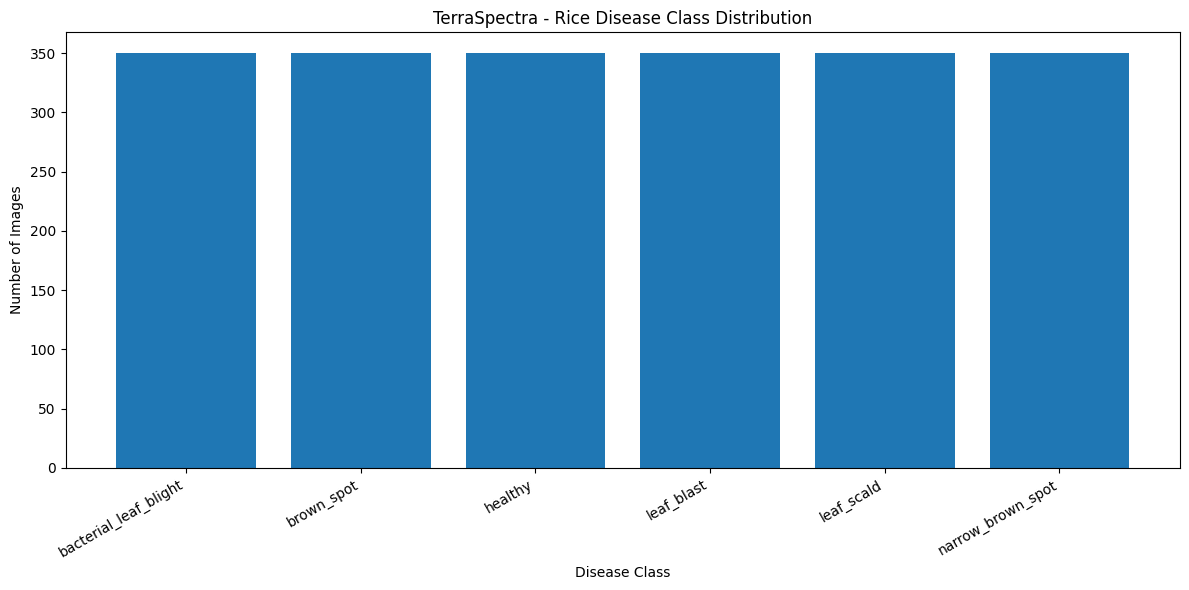

In [63]:
plt.figure(figsize=(12, 6))

plt.bar(
    class_counts.keys(),
    class_counts.values()
)

plt.xlabel("Disease Class")
plt.ylabel("Number of Images")

plt.title(
    "TerraSpectra - Rice Disease Class Distribution"
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.tight_layout()

plt.show()

In [64]:
all_image_paths = []
all_labels = []

class_to_index = {
    class_name: i
    for i, class_name in enumerate(classes)
}

for class_name in classes:

    class_path = os.path.join(
        TRAIN_DIR,
        class_name
    )

    for file in os.listdir(class_path):

        if file.lower().endswith(
            (".jpg", ".jpeg", ".png")
        ):

            image_path = os.path.join(
                class_path,
                file
            )

            all_image_paths.append(
                image_path
            )

            all_labels.append(
                class_to_index[class_name]
            )

print(
    "Total images:",
    len(all_image_paths)
)

print(
    "Total labels:",
    len(all_labels)
)

Total images: 2100
Total labels: 2100


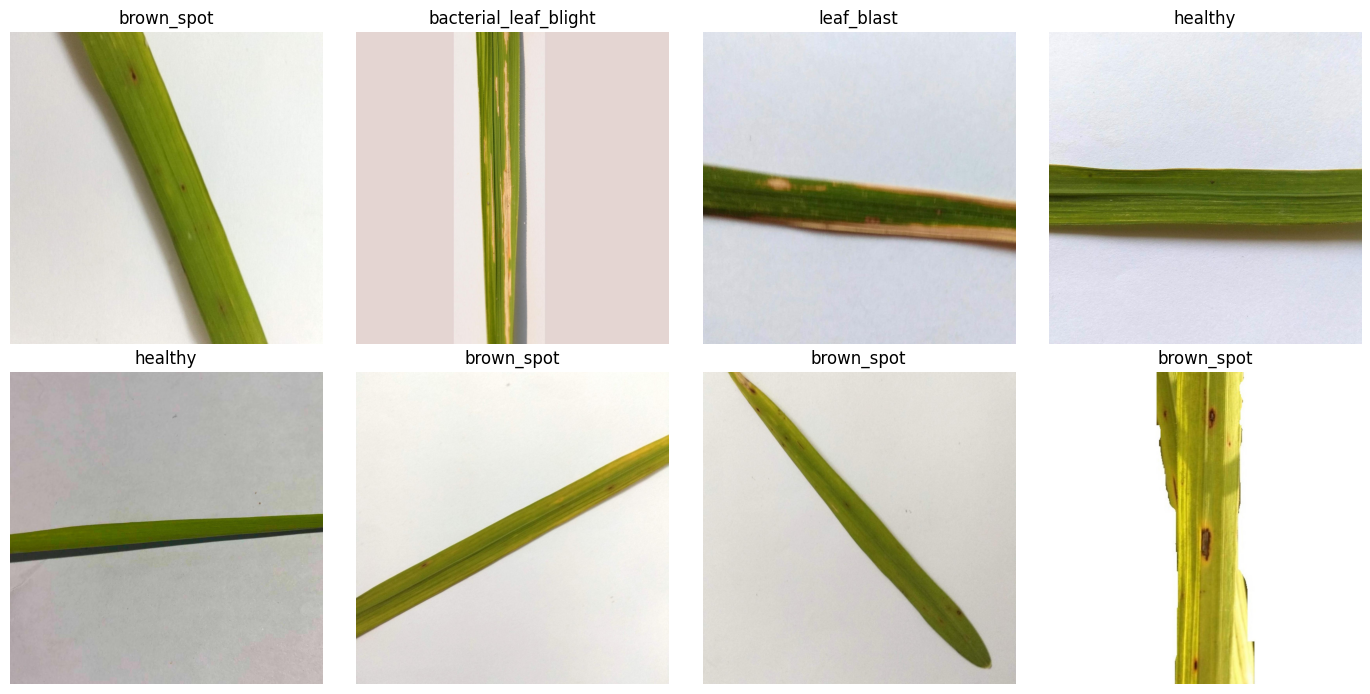

In [65]:
sample_indices = random.sample(
    range(len(all_image_paths)),
    min(8, len(all_image_paths))
)

fig, axes = plt.subplots(
    2,
    4,
    figsize=(14, 7)
)

for ax, idx in zip(
    axes.flat,
    sample_indices
):

    image = Image.open(
        all_image_paths[idx]
    ).convert("RGB")

    ax.imshow(image)

    ax.set_title(
        classes[all_labels[idx]]
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [66]:
image_sizes = []

sample_for_size = random.sample(
    all_image_paths,
    min(100, len(all_image_paths))
)

for image_path in sample_for_size:

    try:

        image = Image.open(
            image_path
        )

        image_sizes.append(
            image.size
        )

    except:
        pass

print(
    "Most common image sizes:"
)

print(
    Counter(image_sizes).most_common(10)
)

Most common image sizes:
[((1600, 1600), 100)]


In [67]:
IMAGE_SIZE = 224

In [68]:
train_transform = transforms.Compose([

    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        15
    ),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],
        std=[
            0.229,
            0.224,
            0.225
        ]
    )
])

print("Training preprocessing ready.")

Training preprocessing ready.


In [69]:
val_transform = transforms.Compose([

    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],
        std=[
            0.229,
            0.224,
            0.225
        ]
    )
])

print("Validation preprocessing ready.")

Validation preprocessing ready.


In [70]:
train_full_dataset = datasets.ImageFolder(
    TRAIN_DIR,
    transform=train_transform
)

val_full_dataset = datasets.ImageFolder(
    TRAIN_DIR,
    transform=val_transform
)

print(
    "Images:",
    len(train_full_dataset)
)

print(
    "Classes:",
    train_full_dataset.classes
)

Images: 2100
Classes: ['bacterial_leaf_blight', 'brown_spot', 'healthy', 'leaf_blast', 'leaf_scald', 'narrow_brown_spot']


In [71]:
indices = np.arange(
    len(train_full_dataset)
)

targets = np.array(
    train_full_dataset.targets
)

train_indices, val_indices = train_test_split(

    indices,

    test_size=0.20,

    random_state=SEED,

    stratify=targets
)

print(
    "Training:",
    len(train_indices)
)

print(
    "Validation:",
    len(val_indices)
)

Training: 1680
Validation: 420


In [72]:
train_dataset = Subset(
    train_full_dataset,
    train_indices
)

val_dataset = Subset(
    val_full_dataset,
    val_indices
)

print(
    "Train images:",
    len(train_dataset)
)

print(
    "Validation images:",
    len(val_dataset)
)

Train images: 1680
Validation images: 420


In [73]:
BATCH_SIZE = 32

if device.type == "cuda":
    NUM_WORKERS = 2
else:
    NUM_WORKERS = 0

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

print("DataLoaders created.")

DataLoaders created.


In [74]:
images, labels = next(
    iter(train_loader)
)

print(
    "Image tensor shape:",
    images.shape
)

print(
    "Label tensor shape:",
    labels.shape
)

print(
    "Data type:",
    images.dtype
)

Image tensor shape: torch.Size([32, 3, 224, 224])
Label tensor shape: torch.Size([32])
Data type: torch.float32


In [75]:
def denormalize(image):

    mean = torch.tensor(
        [0.485, 0.456, 0.406]
    ).view(3, 1, 1)

    std = torch.tensor(
        [0.229, 0.224, 0.225]
    ).view(3, 1, 1)

    image = image * std + mean

    return torch.clamp(
        image,
        0,
        1
    )

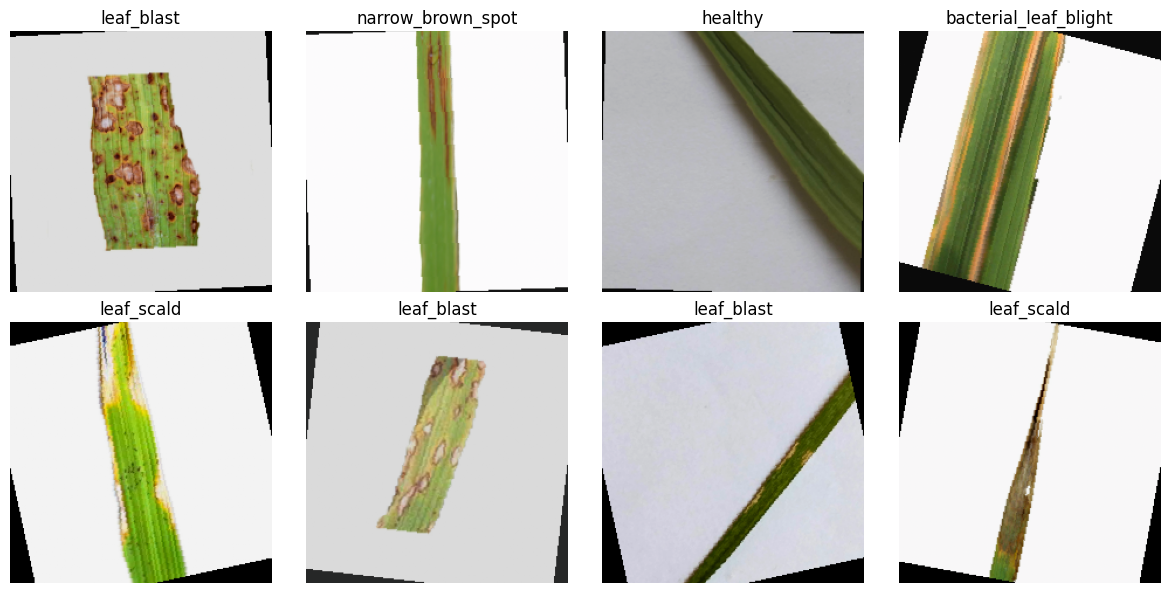

In [76]:
fig, axes = plt.subplots(
    2,
    4,
    figsize=(12, 6)
)

for i, ax in enumerate(
    axes.flat
):

    image = denormalize(
        images[i].cpu()
    )

    ax.imshow(
        image.permute(1, 2, 0)
    )

    ax.set_title(
        classes[labels[i].item()]
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

# WEEK 2

In [77]:
class TerraSpectraCNN(nn.Module):

    def __init__(
        self,
        num_classes
    ):

        super().__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(
                3,
                32,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(32),

            nn.ReLU(),

            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(
                32,
                64,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(64),

            nn.ReLU(),

            nn.MaxPool2d(2),

            # Block 3
            nn.Conv2d(
                64,
                128,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(128),

            nn.ReLU(),

            nn.MaxPool2d(2),

            # Block 4
            nn.Conv2d(
                128,
                256,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(256),

            nn.ReLU(),

            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(

            nn.AdaptiveAvgPool2d(
                (1, 1)
            ),

            nn.Flatten(),

            nn.Linear(
                256,
                128
            ),

            nn.ReLU(),

            nn.Dropout(
                0.4
            ),

            nn.Linear(
                128,
                num_classes
            )
        )

    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x

In [78]:
model = TerraSpectraCNN(
    NUM_CLASSES
)

model = model.to(device)

print(model)

TerraSpectraCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats

In [79]:
total_parameters = sum(
    p.numel()
    for p in model.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(
    "Total parameters:",
    total_parameters
)

print(
    "Trainable parameters:",
    trainable_parameters
)

Total parameters: 423046
Trainable parameters: 423046


In [80]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

print("Loss:", criterion)
print("Optimizer:", optimizer)

Loss: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)


In [81]:
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

In [82]:
def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    progress = tqdm(
        loader,
        desc="Training",
        leave=False
    )

    for images, labels in progress:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad()

        outputs = model(
            images
        )

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        total_loss += (
            loss.item()
            *
            images.size(0)
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

        progress.set_postfix(
            loss=loss.item()
        )

    epoch_loss = (
        total_loss / total
    )

    epoch_accuracy = (
        correct / total
    )

    return (
        epoch_loss,
        epoch_accuracy
    )

In [83]:
def validate_model(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for images, labels in tqdm(
            loader,
            desc="Validation",
            leave=False
        ):

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            outputs = model(
                images
            )

            loss = criterion(
                outputs,
                labels
            )

            total_loss += (
                loss.item()
                *
                images.size(0)
            )

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

    epoch_loss = (
        total_loss / total
    )

    epoch_accuracy = (
        correct / total
    )

    return (
        epoch_loss,
        epoch_accuracy,
        all_labels,
        all_predictions
    )

In [84]:
if device.type == "cuda":
    EPOCHS = 10
else:
    EPOCHS = 5

print(
    "Epochs:",
    EPOCHS
)

Epochs: 5


In [86]:
best_val_accuracy = 0.0

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

BEST_MODEL_PATH = "/content/terraspectra_cnn_best.pth"

for epoch in range(EPOCHS):

    print()
    print("=" * 60)

    print(
        f"Epoch {epoch + 1}/{EPOCHS}"
    )

    print("=" * 60)

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    (
        val_loss,
        val_accuracy,
        val_labels,
        val_predictions
    ) = validate_model(
        model,
        val_loader,
        criterion,
        device
    )

    scheduler.step(
        val_accuracy
    )

    train_losses.append(
        train_loss
    )

    val_losses.append(
        val_loss
    )

    train_accuracies.append(
        train_accuracy
    )

    val_accuracies.append(
        val_accuracy
    )

    print()
    print(
        f"Train Loss     : {train_loss:.4f}"
    )

    print(
        f"Train Accuracy : {train_accuracy:.4f}"
    )

    print(
        f"Val Loss       : {val_loss:.4f}"
    )

    print(
        f"Val Accuracy   : {val_accuracy:.4f}"
    )

    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save(
            model.state_dict(),
            BEST_MODEL_PATH
        )


        print(
            "✓ Best model saved"
        )

print()
print(
    "Best validation accuracy:",
    best_val_accuracy
)


Epoch 1/5


Training:   0%|          | 0/53 [00:00<?, ?it/s]

Validation:   0%|          | 0/14 [00:00<?, ?it/s]


Train Loss     : 0.6301
Train Accuracy : 0.7679
Val Loss       : 1.4531
Val Accuracy   : 0.4762
✓ Best model saved

Epoch 2/5


Training:   0%|          | 0/53 [00:00<?, ?it/s]

Validation:   0%|          | 0/14 [00:00<?, ?it/s]

... (6 outputs left out)


Train Loss     : 0.5053
Train Accuracy : 0.8149
Val Loss       : 0.7329
Val Accuracy   : 0.7095
✓ Best model saved

Epoch 5/5


Training:   0%|          | 0/53 [00:00<?, ?it/s]

Validation:   0%|          | 0/14 [00:00<?, ?it/s]


Train Loss     : 0.4930
Train Accuracy : 0.8101
Val Loss       : 0.4666
Val Accuracy   : 0.8071
✓ Best model saved

Best validation accuracy: 0.8071428571428572


In [87]:
model.load_state_dict(
    torch.load(
        BEST_MODEL_PATH,
        map_location=device
    )
)

model.eval()

print(
    "Best CNN model loaded."
)

Best CNN model loaded.


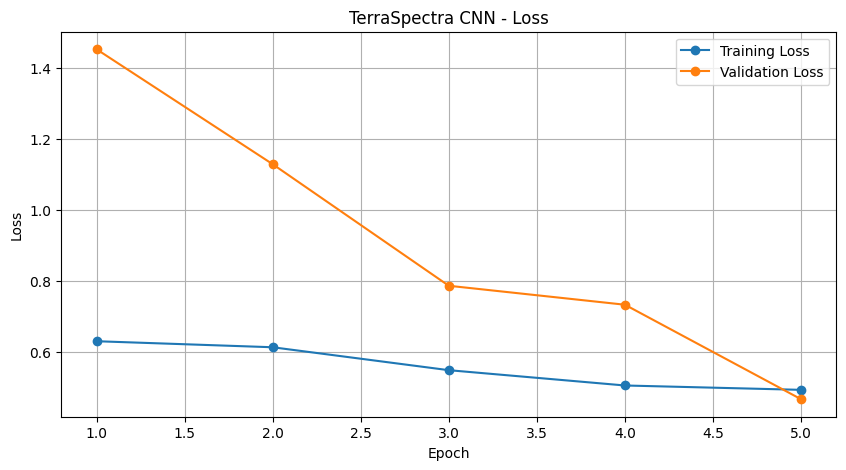

In [88]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, EPOCHS + 1),
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    range(1, EPOCHS + 1),
    val_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "TerraSpectra CNN - Loss"
)

plt.legend()
plt.grid()

plt.show()

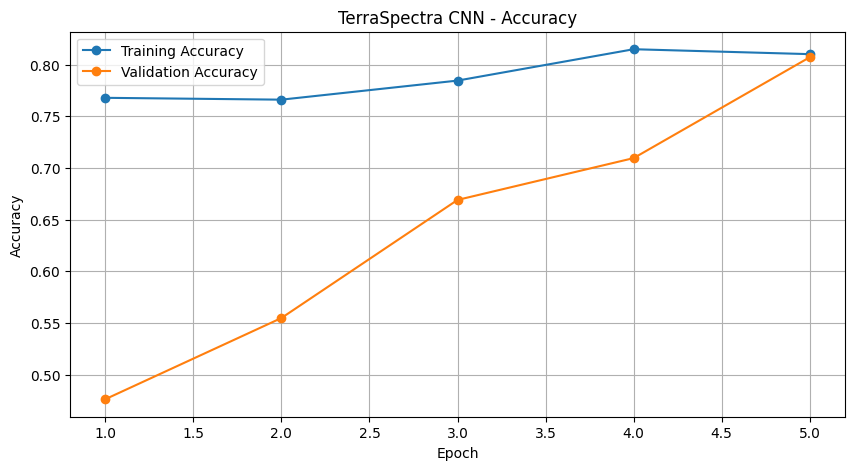

In [89]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, EPOCHS + 1),
    train_accuracies,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    range(1, EPOCHS + 1),
    val_accuracies,
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "TerraSpectra CNN - Accuracy"
)

plt.legend()
plt.grid()

plt.show()

In [90]:
(
    val_loss,
    val_accuracy,
    val_labels,
    val_predictions
) = validate_model(
    model,
    val_loader,
    criterion,
    device
)

precision = precision_score(
    val_labels,
    val_predictions,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    val_labels,
    val_predictions,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    val_labels,
    val_predictions,
    average="weighted",
    zero_division=0
)

print("=" * 50)
print("TERRASPECTRA CNN RESULTS")
print("=" * 50)

print(
    f"Accuracy  : {val_accuracy * 100:.2f}%"
)

print(
    f"Precision : {precision * 100:.2f}%"
)

print(
    f"Recall    : {recall * 100:.2f}%"
)

print(
    f"F1 Score  : {f1 * 100:.2f}%"
)

Validation:   0%|          | 0/14 [00:00<?, ?it/s]

TERRASPECTRA CNN RESULTS
Accuracy  : 80.71%
Precision : 80.66%
Recall    : 80.71%
F1 Score  : 80.41%


In [91]:
print(
    classification_report(
        val_labels,
        val_predictions,
        target_names=classes,
        digits=4,
        zero_division=0
    )
)

                       precision    recall  f1-score   support

bacterial_leaf_blight     0.9091    1.0000    0.9524        70
           brown_spot     0.6429    0.6429    0.6429        70
              healthy     0.8205    0.9143    0.8649        70
           leaf_blast     0.5873    0.5286    0.5564        70
           leaf_scald     1.0000    0.8143    0.8976        70
    narrow_brown_spot     0.8800    0.9429    0.9103        70

             accuracy                         0.8071       420
            macro avg     0.8066    0.8071    0.8041       420
         weighted avg     0.8066    0.8071    0.8041       420



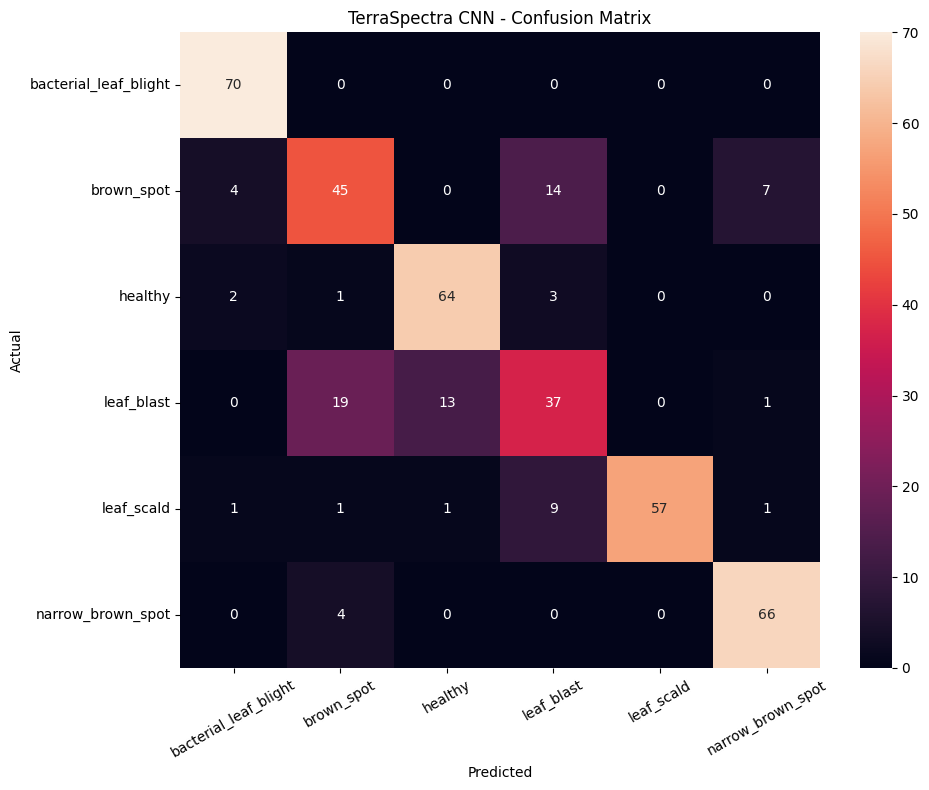

In [92]:
cm = confusion_matrix(
    val_labels,
    val_predictions
)

plt.figure(
    figsize=(10, 8)
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title(
    "TerraSpectra CNN - Confusion Matrix"
)

plt.xticks(rotation=30)
plt.yticks(rotation=0)

plt.tight_layout()

plt.show()

In [93]:
CLASS_NAMES_PATH = (
    "/content/terraspectra_classes.json"
)

with open(
    CLASS_NAMES_PATH,
    "w"
) as file:

    json.dump(
        classes,
        file,
        indent=4
    )

print(
    "Saved:",
    CLASS_NAMES_PATH
)

Saved: /content/terraspectra_classes.json


In [94]:
def predict_image(
    image_path
):

    image = Image.open(
        image_path
    ).convert("RGB")

    image_tensor = val_transform(
        image
    )

    image_tensor = image_tensor.unsqueeze(
        0
    )

    image_tensor = image_tensor.to(
        device
    )

    model.eval()

    with torch.no_grad():

        output = model(
            image_tensor
        )

        probabilities = torch.softmax(
            output,
            dim=1
        )

        confidence, predicted = torch.max(
            probabilities,
            dim=1
        )

    predicted_class = classes[
        predicted.item()
    ]

    confidence_percentage = (
        confidence.item() * 100
    )

    return (
        predicted_class,
        confidence_percentage
    )

In [95]:
random_image = random.choice(
    all_image_paths
)

prediction, confidence = predict_image(
    random_image
)

actual_class = os.path.basename(
    os.path.dirname(
        random_image
    )
)

print(
    "Actual:",
    actual_class
)

print(
    "Predicted:",
    prediction
)

print(
    f"Confidence: {confidence:.2f}%"
)

Actual: narrow_brown_spot
Predicted: narrow_brown_spot
Confidence: 93.69%


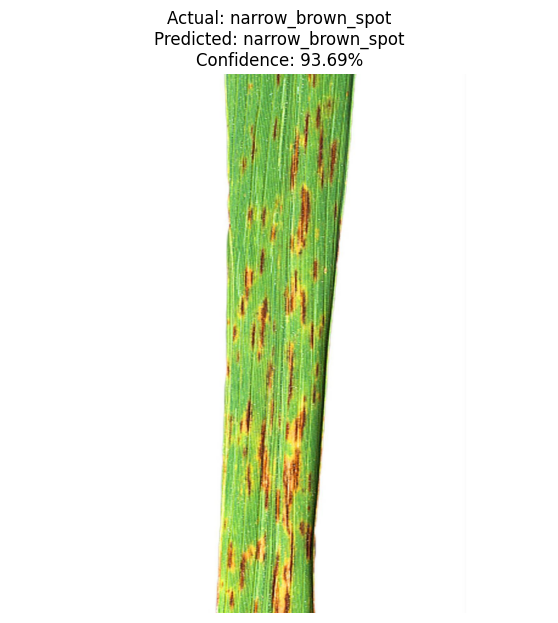

In [96]:
image = Image.open(
    random_image
).convert("RGB")

plt.figure(
    figsize=(7, 7)
)

plt.imshow(image)

plt.title(
    f"Actual: {actual_class}\n"
    f"Predicted: {prediction}\n"
    f"Confidence: {confidence:.2f}%"
)

plt.axis("off")

plt.show()